# Do node and calendar day affect the fulltrace measurements?

We compare recordings **within emotional and within neutral separately**, using all available 70B fulltrace batches and the existing 17 features. Each whole recording is one observation.

The question is whether measurements cluster by **node**, **calendar date**, or both. This is an exploratory analysis of recorded counters, not a test of model answer quality or a causal experiment. Original data and previous analyses are only read. Select the project Python environment (`.mccvenv`) and run all cells; dependencies are NumPy, pandas, SciPy, Matplotlib, and statsmodels.

In [1]:
from pathlib import Path
import sys
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/features/recomputed/fulltrace").is_dir())
sys.path.insert(0, str(ROOT / "analysis/lib"))
from fulltrace_node_day import load_recordings, model_values, analyze, CONDITIONS

TIMEZONE = "America/Chicago"  # Calendar date at the start of each trace.
TEST_BOOTSTRAPS = 5999
INTERVAL_BOOTSTRAPS = 999
WORKERS = 4  # Set to 1 to use a single process.
SEED = 42
OUT = ROOT / "results/fulltrace_node_day_2026-10-21"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 55)

def save_figure(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print(f"Dates: {TIMEZONE}; outputs: {OUT.relative_to(ROOT)}")

Dates: America/Chicago; outputs: results/fulltrace_node_day_2026-10-21


## 1. Which comparisons do we have?

Dates come from raw start timestamps, never file modification times. A trace that crosses midnight belongs to its **start date** and is flagged below. Node IDs come from recording-folder labels; this assumes a given ID identifies the same physical node across reservations.

Only 70B emotional/neutral traces are eligible. Joy and mechanical recordings are excluded. Individual feature CSVs are joined to their original metadata; combined CSVs are not counted again.

In [2]:
df, FEATURES, sources, excluded = load_recordings(ROOT, TIMEZONE)
cells = df.groupby(["condition", "node", "day"]).size().rename("recordings").reset_index()
summary = []
for condition in CONDITIONS:
    sub = df.loc[df.condition == condition]
    node_days = sub.groupby("node").day.nunique()
    summary.append({"condition": condition, "recordings": len(sub),
                    "nodes": sub.node.nunique(), "dates": sub.day.nunique(),
                    "node/date cells": len(cells.loc[cells.condition == condition]),
                    "nodes on multiple dates": int((node_days > 1).sum())})
display(pd.DataFrame(summary).set_index("condition"))
display(pd.crosstab([df.day, df.batch], df.condition))
print(f"Features: {len(FEATURES)}; excluded recordings: {len(excluded)}")
print(f"Traces crossing midnight: {int(df.crosses_midnight.sum())} (assigned to start date)")
# All eligible raw recordings must have matching processed features: loader fails otherwise.
df.to_csv(OUT / "input_recordings.csv", index=False)
sources.to_csv(OUT / "input_checksums.csv", index=False)
excluded.to_csv(OUT / "excluded_recordings.csv", index=False)
cells.to_csv(OUT / "node_date_counts.csv", index=False)

,recordings,nodes,dates,node/date cells,nodes on multiple dates
condition,,,,,
emotional,35,17,7,23,6
neutral,35,17,7,23,6


,condition,emotional,neutral
day,batch,,
2026-05-04,batch_001_en,3,3
2026-05-06,batch_001_en,2,2
2026-05-07,batch_001_en,1,1
2026-05-10,batch_001_en,10,10
2026-05-12,batch_001_en,4,4
2026-09-30,batch_003_enj,10,10
2026-10-12,batch_004_enm,5,5


Features: 17; excluded recordings: 35
Traces crossing midnight: 5 (assigned to start date)


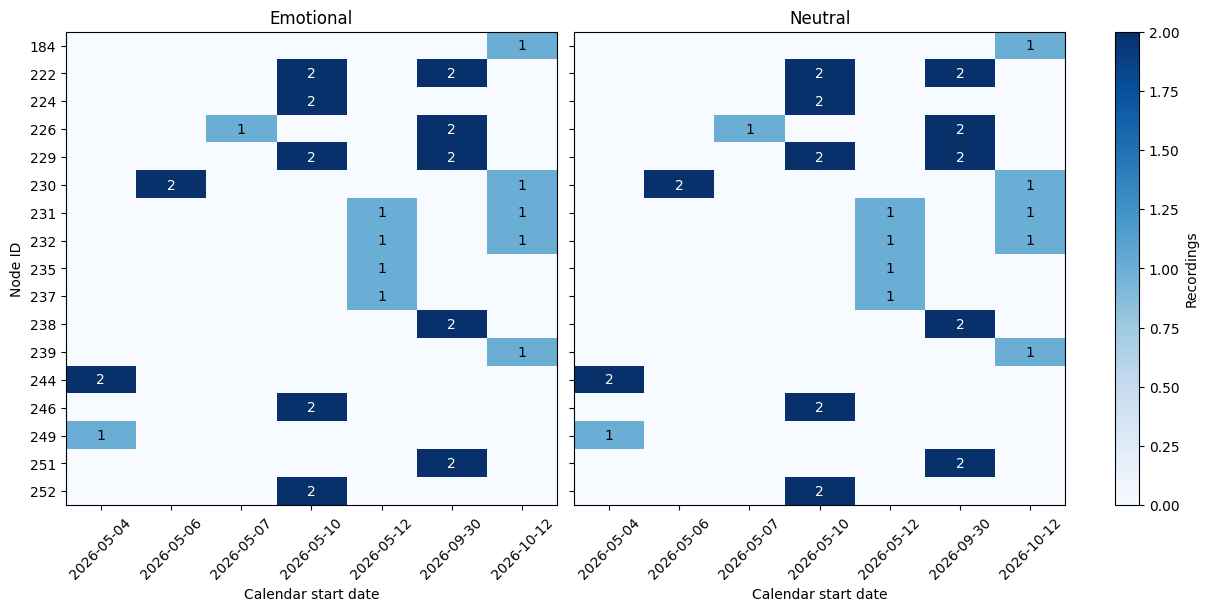

Node/date overlap has 3 disconnected groups.
Batch cannot be separated from a full set of date effects: every date belongs to one batch.


In [3]:
nodes = sorted(df.node.unique(), key=int)
dates = sorted(df.day.unique())
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True, layout="constrained")
for ax, condition in zip(axes, CONDITIONS):
    counts = pd.crosstab(df.loc[df.condition == condition, "node"],
                         df.loc[df.condition == condition, "day"])
    counts = counts.reindex(index=nodes, columns=dates, fill_value=0)
    im = ax.imshow(counts, cmap="Blues", vmin=0, vmax=cells.recordings.max(), aspect="auto")
    for i in range(len(nodes)):
        for j in range(len(dates)):
            if counts.iloc[i, j]: ax.text(j, i, str(counts.iloc[i, j]), ha="center", va="center", color="white" if counts.iloc[i, j] > 1 else "black")
    ax.set(title=condition.title(), xticks=range(len(dates)), xticklabels=dates,
           yticks=range(len(nodes)), yticklabels=nodes, xlabel="Calendar start date")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Node ID")
fig.colorbar(im, ax=axes, label="Recordings")
save_figure(fig, "coverage")

# Count disconnected pieces of the node/date overlap graph.
adjacency = {}
for node, day in df[["node", "day"]].drop_duplicates().itertuples(index=False):
    n, d = "node:" + node, "day:" + day
    adjacency.setdefault(n, set()).add(d)
    adjacency.setdefault(d, set()).add(n)
unseen, components = set(adjacency), 0
while unseen:
    components += 1
    stack = [unseen.pop()]
    while stack:
        for neighbor in adjacency[stack.pop()] & unseen:
            unseen.remove(neighbor)
            stack.append(neighbor)
print(f"Node/date overlap has {components} disconnected groups.")
print("Batch cannot be separated from a full set of date effects: every date belongs to one batch.")

## 2. How do measurements change within each condition?

Rates, variances, and throttle-per-cycle are analysed on a **log scale** to reduce skew. Entropy and slopes keep their original scales. A log-scale comparison concerns proportional changes. No extraction formulas are changed.

In the first heatmap, each row is one node/date cell, averaging repeated traces on the analysis scale. Each feature is standardized within its condition: red is higher, blue lower. Color is clipped at ±3 standard deviations for readability; exported values are not clipped. The model below still uses individual recordings.

The second heatmap compares the **same node on later versus earlier dates**. These comparisons also cross collection batches. They are descriptive, not independent evidence of a pure day effect.

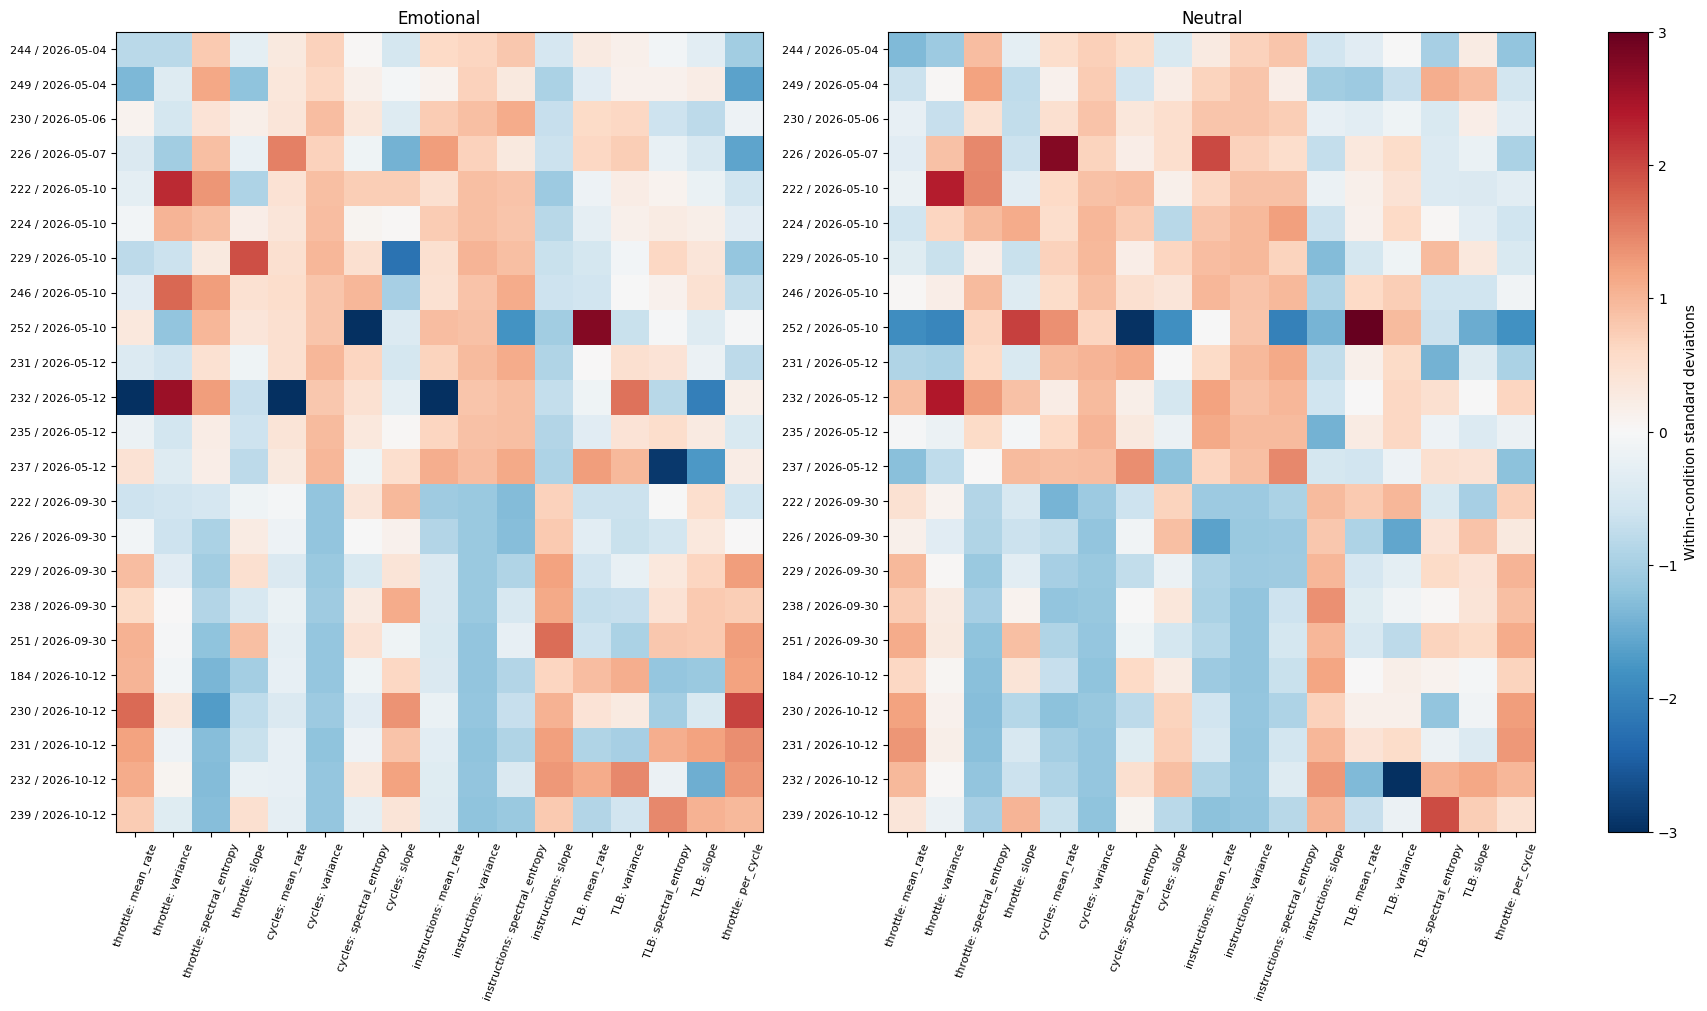

In [4]:
transformed = df[["condition", "node", "day", "batch", "run_label"]].copy()
labels = []
for feature in FEATURES:
    transformed[feature], _ = model_values(df[feature], feature)
    indicator, metric = feature.rsplit("__", 1)
    indicator = {"core_power.throttle": "throttle", "tlb:tlb_flush": "TLB"}.get(indicator, indicator)
    labels.append(f"{indicator}: {metric}")

z = transformed.copy()
for condition in CONDITIONS:
    mask = z.condition == condition
    values = z.loc[mask, FEATURES]
    z.loc[mask, FEATURES] = (values - values.mean()) / values.std(ddof=0).replace(0, np.nan)
cell_means = z.groupby(["condition", "day", "node"])[FEATURES].mean()
cell_means.to_csv(OUT / "node_date_feature_zscores.csv")
fig, axes = plt.subplots(1, 2, figsize=(17, 10), layout="constrained")
for ax, condition in zip(axes, CONDITIONS):
    values = cell_means.loc[condition]
    im = ax.imshow(values, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
    ax.set(title=condition.title(), xticks=range(len(FEATURES)), xticklabels=labels,
           yticks=range(len(values)), yticklabels=[f"{n} / {d}" for d, n in values.index])
    ax.tick_params(axis="x", labelrotation=70, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
fig.colorbar(im, ax=axes, label="Within-condition standard deviations")
save_figure(fig, "node_date_features")

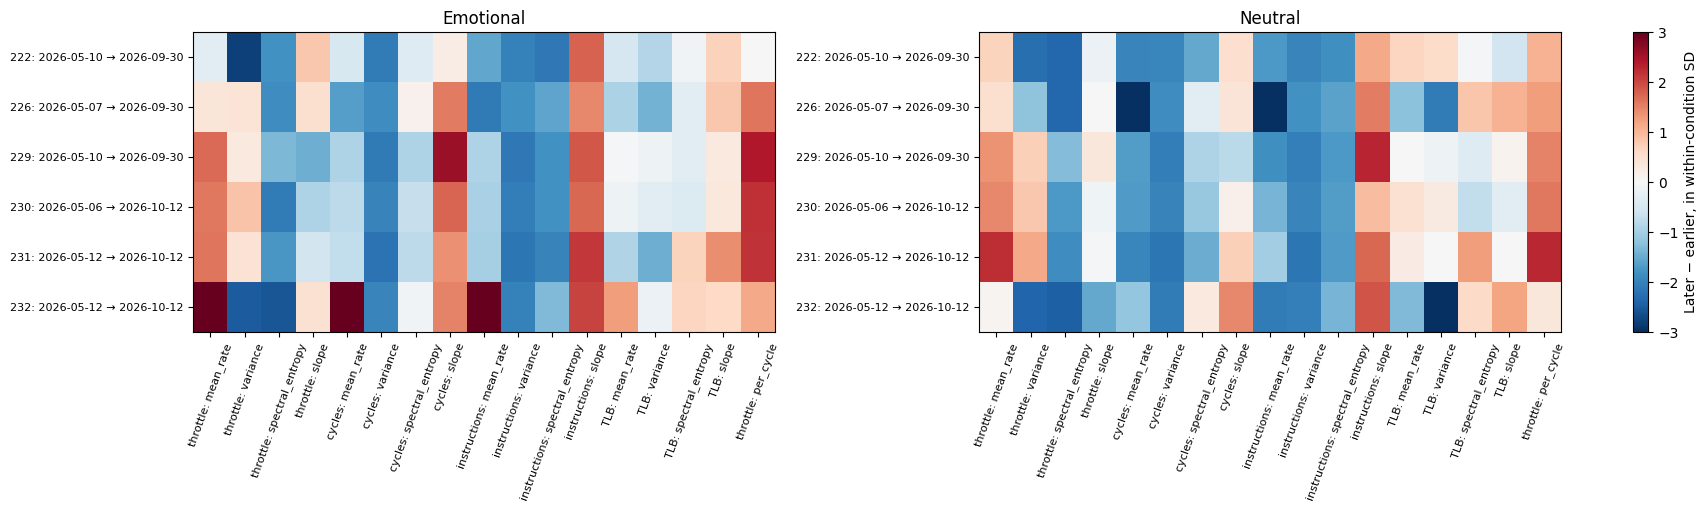

In [5]:
changes = []
for (condition, node), sub in transformed.groupby(["condition", "node"]):
    means = sub.groupby("day")[FEATURES].mean().sort_index()
    if len(means) < 2: continue
    # Every available pair; currently each repeated node has exactly two dates.
    from itertools import combinations
    for earlier, later in combinations(means.index, 2):
        for feature in FEATURES:
            delta = means.loc[later, feature] - means.loc[earlier, feature]
            sd = transformed.loc[transformed.condition == condition, feature].std(ddof=0)
            changes.append({"condition": condition, "node": node, "earlier": earlier,
                            "later": later, "feature": feature, "delta_analysis_scale": delta,
                            "delta_condition_sd": delta / sd if sd else np.nan})
changes = pd.DataFrame(changes)
changes.to_csv(OUT / "same_node_cross_date_changes.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(17, 5), layout="constrained")
for ax, condition in zip(axes, CONDITIONS):
    table = changes.loc[changes.condition == condition].pivot(
        index=["node", "earlier", "later"], columns="feature", values="delta_condition_sd")
    table = table.reindex(columns=FEATURES)
    im = ax.imshow(table, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
    ax.set(title=condition.title(), xticks=range(len(FEATURES)), xticklabels=labels,
           yticks=range(len(table)),
           yticklabels=[f"{n}: {a} → {b}" for n, a, b in table.index])
    ax.tick_params(axis="x", labelrotation=70, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
fig.colorbar(im, ax=axes, label="Later − earlier, in within-condition SD")
save_figure(fig, "same_node_cross_date")

## 3. Statistical question and method

For **each condition and feature separately**, fit a crossed random-intercept model:

> measurement = average + node offset + calendar-date offset + remaining variation

Nodes and dates are categorical groups. They are not a time trend and dates are not nested inside nodes. The model assumes independent, approximately Gaussian node/date offsets and remaining errors on the chosen analysis scale. It estimates the fraction of variation associated with each grouping. These fractions depend on those assumptions, especially with only seven dates and limited overlap.

- **Node test:** does adding node variation improve a model that already includes date?
- **Date test:** does adding date variation improve a model that already includes node?

We use maximum likelihood and **parametric-bootstrap likelihood-ratio tests**: simulate from the model without the tested component, then refit both models from multiple starting values. This allows valid zero-variance boundary estimates without using the usual chi-square shortcut. A separate bootstrap from the full model supplies approximate, pointwise 95% intervals for the variance fractions. Fit failures abort the analysis rather than being silently discarded.

**Holm correction covers all 68 planned tests together**: 17 features × two conditions × two effects. The code reports Monte Carlo uncertainty from the finite number of simulations. Computation may take several minutes.

Batch is not added as another effect because it overlaps the calendar-date grouping. We do not estimate a node×date interaction from these sparse cells. Remaining variation includes effects the model does not explain.

Methods: [crossed variance components](https://www.statsmodels.org/stable/mixed_linear.html), [boundary/singular-fit cautions](https://lme4.github.io/lme4/reference/isSingular.html), [model-based bootstrap](https://lme4.github.io/lme4/reference/bootMer.html). The numerical fitting code is in `analysis/lib/fulltrace_node_day.py`.

In [6]:
estimates, tests, residuals = analyze(
    df, FEATURES, test_repeats=TEST_BOOTSTRAPS,
    interval_repeats=INTERVAL_BOOTSTRAPS, seed=SEED, workers=WORKERS,
)
estimates.to_csv(OUT / "variance_components.csv", index=False)
tests.to_csv(OUT / "bootstrap_tests.csv", index=False)
residuals.to_csv(OUT / "conditional_residuals.csv", index=False)

configuration = dict(timezone=TIMEZONE, date_rule="trace start date", seed=SEED,
                     test_bootstraps=TEST_BOOTSTRAPS, interval_bootstraps=INTERVAL_BOOTSTRAPS, workers=WORKERS,
                     correction="Holm across all feature/condition/node-or-day tests",
                     features=FEATURES, n_recordings=len(df), model="Gaussian crossed random intercepts; ML")
(OUT / "configuration.json").write_text(json.dumps(configuration, indent=2) + "\n")
print("Saved estimates, corrected tests, residuals, and configuration.")

Completed bootstrap results retained; diagnostic residuals refreshed and checked against fitted offsets.


## 4. What can we conclude?

The table shows estimated variance shares and approximate 95% intervals on the **analysis scale**. For example, a 40% date share means the model attributes 40% of variation to differences between sampled dates; it does not mean the measurement increased by 40%.

A corrected p-value below 0.05 supports an association under the model. A larger p-value means insufficient evidence, **not proof that recordings are stable**. Demonstrating stability requires a scientifically acceptable difference and an equivalence analysis.

Intervals are pointwise, model-based uncertainty summaries; they are not corrected for multiple comparisons. Zero component estimates are allowed. Broad intervals, poor residual diagnostics, or Monte Carlo sensitivity call for caution.

**Emotional**

,node share [95% interval],day share [95% interval],residual share [95% interval],node corrected p,day corrected p
feature,,,,,
core_power.throttle__mean_rate,"4% [0, 46]","37% [0, 66]","59% [25, 100]",1.0000,0.2800
core_power.throttle__variance,"34% [0, 70]","11% [0, 42]","56% [22, 100]",1.0000,1.0000
core_power.throttle__spectral_entropy,"7% [0, 32]","88% [49, 95]","6% [2, 25]",0.1225,0.0113
core_power.throttle__slope,"4% [0, 46]","0% [0, 23]","96% [51, 100]",1.0000,1.0000
cycles__mean_rate,"9% [0, 51]","9% [0, 35]","82% [41, 100]",1.0000,1.0000
cycles__variance,"0% [0, 1]","99% [96, 100]","0% [0, 3]",1.0000,0.0113
cycles__spectral_entropy,"78% [43, 90]","0% [0, 17]","22% [8, 56]",0.0173,1.0000
cycles__slope,"10% [0, 49]","22% [0, 53]","68% [32, 100]",1.0000,0.6825
instructions__mean_rate,"15% [0, 53]","22% [0, 55]","64% [27, 100]",1.0000,0.5483


**Neutral**

,node share [95% interval],day share [95% interval],residual share [95% interval],node corrected p,day corrected p
feature,,,,,
core_power.throttle__mean_rate,"0% [0, 39]","35% [0, 64]","65% [29, 100]",1.0000,0.0935
core_power.throttle__variance,"33% [0, 65]","0% [0, 26]","67% [31, 100]",1.0000,1.0000
core_power.throttle__spectral_entropy,"5% [0, 25]","89% [55, 96]","6% [2, 28]",0.5520,0.0113
core_power.throttle__slope,"25% [0, 60]","0% [0, 26]","75% [37, 100]",1.0000,1.0000
cycles__mean_rate,"1% [0, 16]","89% [46, 95]","10% [4, 46]",1.0000,0.0113
cycles__variance,"1% [0, 3]","99% [94, 100]","1% [0, 4]",0.8680,0.0113
cycles__spectral_entropy,"39% [0, 70]","1% [0, 31]","59% [24, 100]",1.0000,1.0000
cycles__slope,"0% [0, 42]","0% [0, 21]","100% [55, 100]",1.0000,1.0000
instructions__mean_rate,"0% [0, 18]","79% [25, 91]","21% [7, 68]",1.0000,0.0113


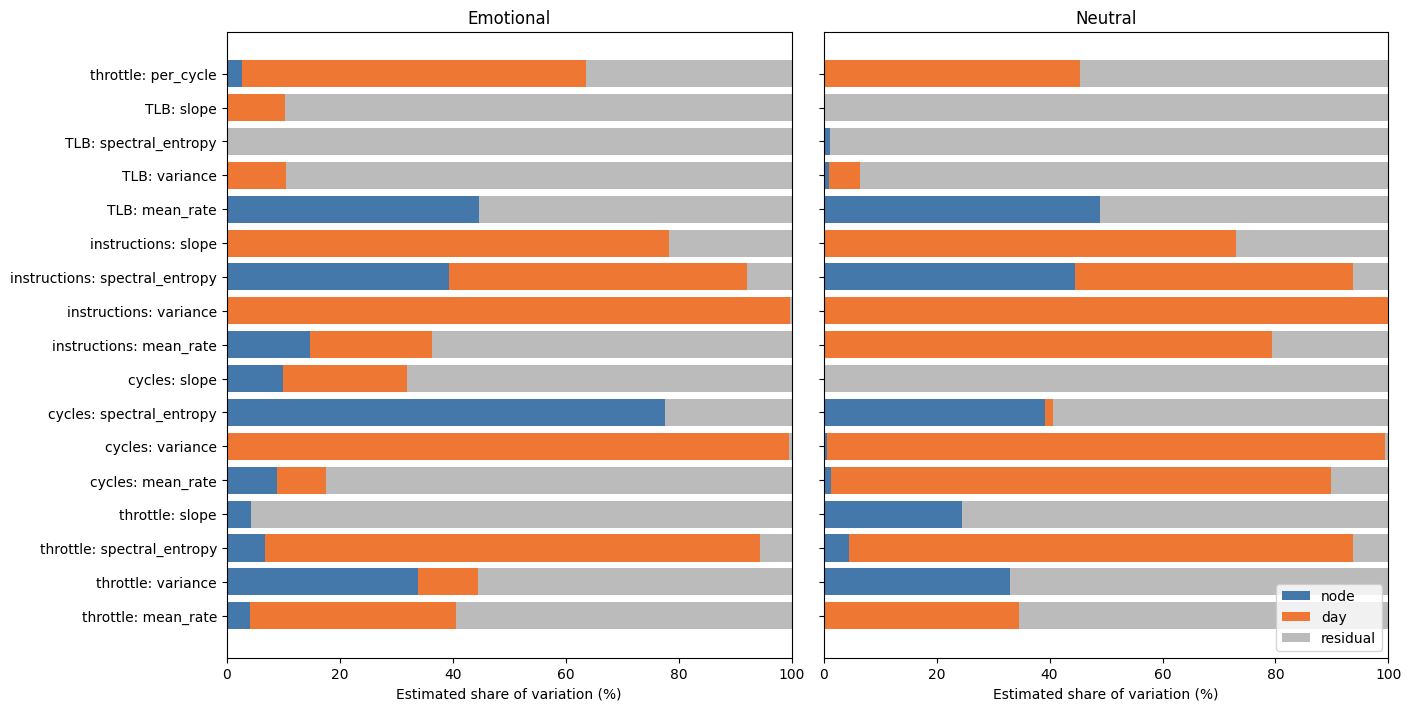

In [7]:
report = estimates[["condition", "feature"]].copy()
for effect in ("node", "day", "residual"):
    report[f"{effect} share [95% interval]"] = estimates.apply(
        lambda r: f"{100*r[f'{effect}_fraction']:.0f}% [{100*r[f'{effect}_low']:.0f}, {100*r[f'{effect}_high']:.0f}]"
        if r.status == "fitted" else "not estimable", axis=1)
for effect in ("node", "day"):
    lookup = tests.loc[tests.effect == effect].set_index(["condition", "feature"]).p_holm
    report[f"{effect} corrected p"] = [lookup.loc[(c, f)] for c, f in report[["condition", "feature"]].itertuples(index=False)]
for condition in CONDITIONS:
    display(Markdown(f"**{condition.title()}**"))
    display(report.loc[report.condition == condition].drop(columns="condition").set_index("feature").round(4))
report.to_csv(OUT / "readable_summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True, layout="constrained")
for ax, condition in zip(axes, CONDITIONS):
    table = estimates.loc[estimates.condition == condition].set_index("feature").reindex(FEATURES)
    left = np.zeros(len(FEATURES))
    for effect, color in [("node", "#4477AA"), ("day", "#EE7733"), ("residual", "#BBBBBB")]:
        values = table[f"{effect}_fraction"].to_numpy() * 100
        ax.barh(range(len(FEATURES)), values, left=left, label=effect, color=color)
        left += values
    ax.set(title=condition.title(), xlim=(0, 100), yticks=range(len(FEATURES)),
           yticklabels=labels, xlabel="Estimated share of variation (%)")
    ax.invert_yaxis()
axes[1].legend(loc="lower right")
save_figure(fig, "variance_shares")

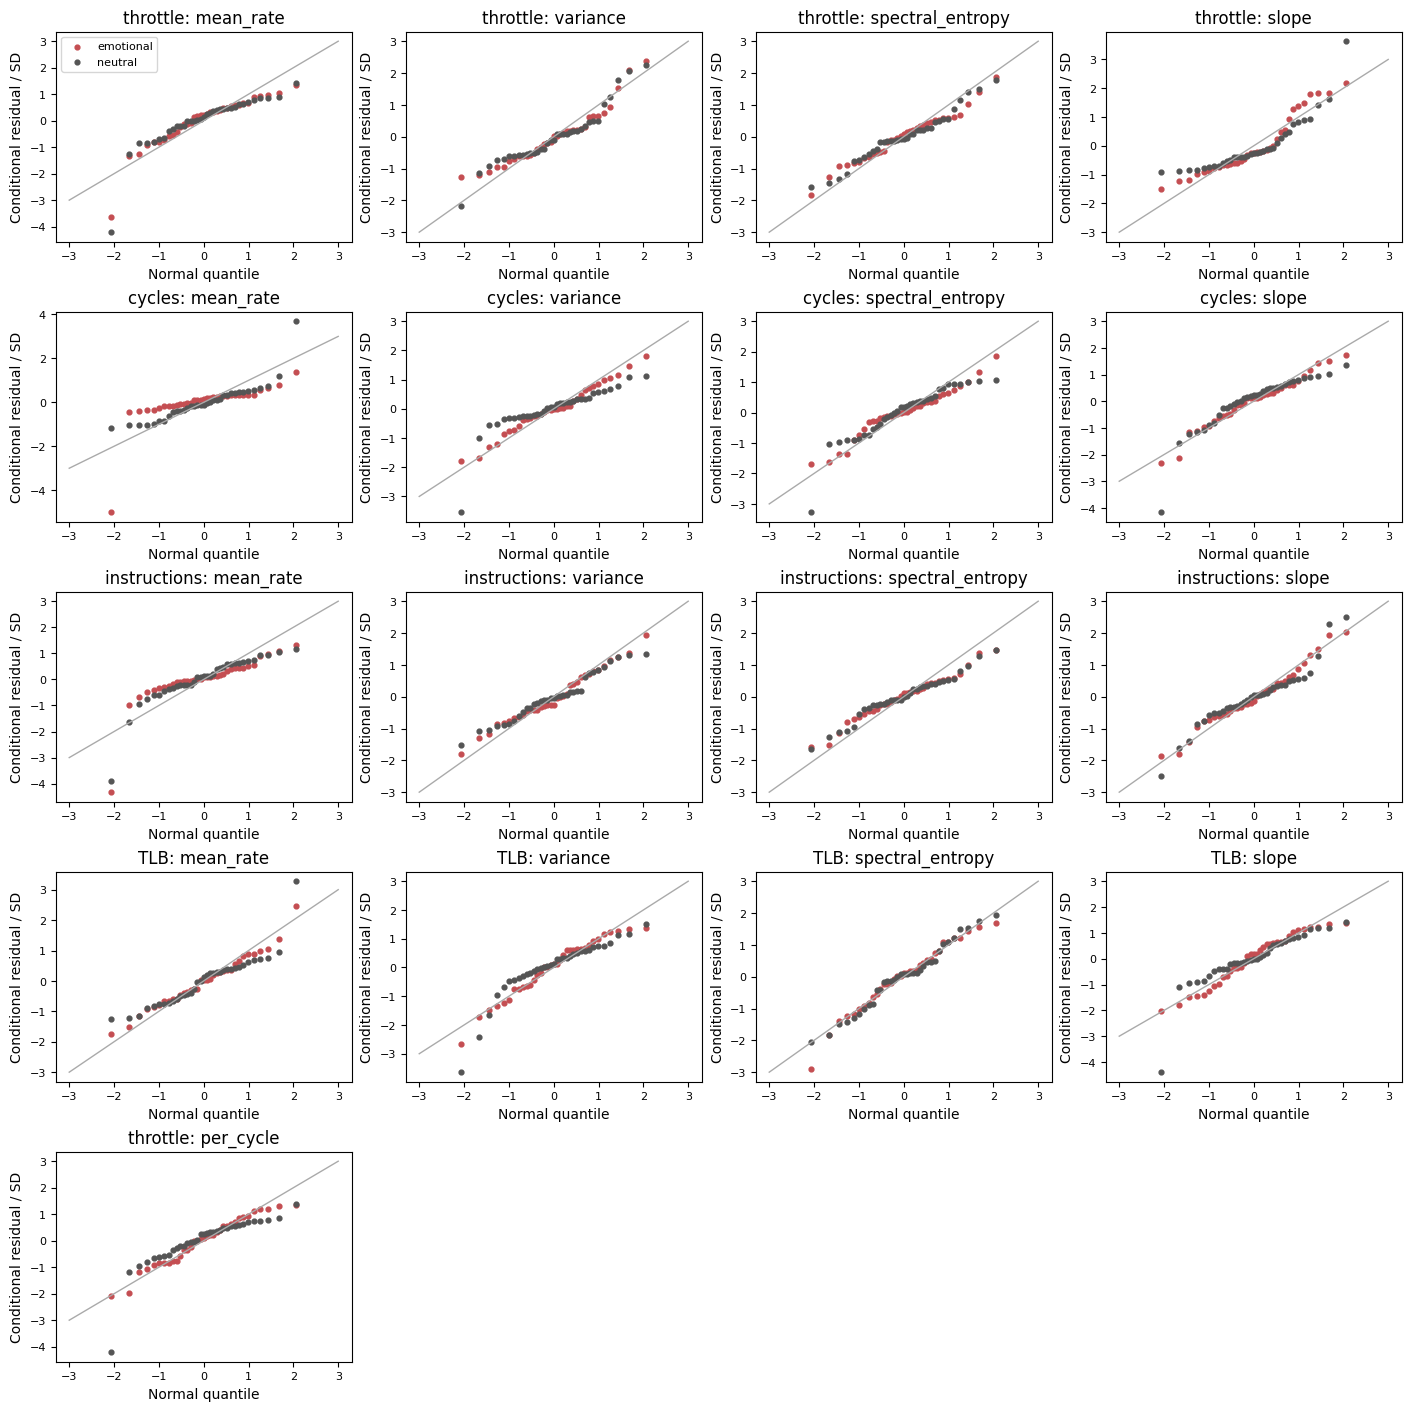

**Emotional:** node-associated variation passes correction for **2/17 features**; date-associated variation for **6/17 features**. These are within-condition associations.

**Neutral:** node-associated variation passes correction for **1/17 features**; date-associated variation for **8/17 features**. These are within-condition associations.

Tests with corrected p < 0.05:


,condition,feature,effect,p_holm,mc_decision_uncertain
5,emotional,core_power.throttle__spectral_entropy,day,0.01133,False
11,emotional,cycles__variance,day,0.01133,False
12,emotional,cycles__spectral_entropy,node,0.01733,False
19,emotional,instructions__variance,day,0.01133,False
20,emotional,instructions__spectral_entropy,node,0.01133,False
21,emotional,instructions__spectral_entropy,day,0.01133,False
23,emotional,instructions__slope,day,0.01133,False
33,emotional,core_power.throttle__per_cycle,day,0.01133,False
39,neutral,core_power.throttle__spectral_entropy,day,0.01133,False
43,neutral,cycles__mean_rate,day,0.01133,False


Monte Carlo-sensitive decisions: 1
Zero/near-zero node or date estimates: 15/34 fits
Fits with a conditional residual beyond 3 SD: 14
All input metadata and feature checksums are unchanged.


In [8]:
# Q–Q plots are an assumption check, not another significance screen.
fig, axes = plt.subplots(5, 4, figsize=(14, 14), layout="constrained")
for ax, feature, label in zip(axes.flat, FEATURES, labels):
    for condition, color in [("emotional", "#C44E52"), ("neutral", "#555555")]:
        values = residuals.loc[(residuals.condition == condition) & (residuals.feature == feature), "residual_sd"]
        theoretical, ordered = stats.probplot(values, fit=False)
        ax.scatter(theoretical, ordered, s=12, color=color, label=condition)
    ax.plot([-3, 3], [-3, 3], color="#AAAAAA", linewidth=1)
    ax.set(title=label, xlabel="Normal quantile", ylabel="Conditional residual / SD")
    ax.tick_params(labelsize=8)
for ax in list(axes.flat)[len(FEATURES):]: ax.set_visible(False)
axes.flat[0].legend(fontsize=8)
save_figure(fig, "residual_diagnostics")

supported = tests.loc[tests.supported, ["condition", "feature", "effect", "p_holm", "mc_decision_uncertain"]]
for condition in CONDITIONS:
    selected = supported.loc[supported.condition == condition]
    node_count = int((selected.effect == "node").sum())
    day_count = int((selected.effect == "day").sum())
    display(Markdown(f"**{condition.title()}:** node-associated variation passes correction for "
                     f"**{node_count}/{len(FEATURES)} features**; date-associated variation for "
                     f"**{day_count}/{len(FEATURES)} features**. These are within-condition associations."))
print("Tests with corrected p < 0.05:")
display(supported.round(5))
print(f"Monte Carlo-sensitive decisions: {int(tests.mc_decision_uncertain.sum())}")
print(f"Zero/near-zero node or date estimates: {int(estimates.boundary_estimate.sum())}/{len(estimates)} fits")
print(f"Fits with a conditional residual beyond 3 SD: {int((estimates.max_abs_residual_sd > 3).sum())}")

# Verify that analysis inputs were not modified during execution.
for source in sources.itertuples(index=False):
    assert hashlib.sha256((ROOT / source.path).read_bytes()).hexdigest() == source.sha256
print("All input metadata and feature checksums are unchanged.")

**Interpretation limits.** Only six nodes recur on different dates, all across collection batches, and the node/date overlap has disconnected groups. Therefore separate variance shares rely on the random-effects assumptions: they are exploratory estimates, not a clean experimental separation of hardware from day. Date-associated variation can include batch, configuration, collection order, and background activity. Residual Q–Q plots are a rough check; their apparent normality cannot establish the assumptions.

For stronger evidence, record the same physical nodes on several shared calendar dates, with repeated emotional and neutral runs on every node/date, consistent settings, and randomized condition order.

All outputs are in `results/fulltrace_node_day_2026-10-21/`. Rerunning this notebook replaces only its own exports. Source recordings, features, and earlier analyses are preserved.